# Chapter 8: Social Choice, Voting, and Impossibility

This notebook reruns four worked examples from the chapter: an agenda that picks the winner, single-peaked preferences that restore a majority order, the median budget against challengers, and the cycle created by rights plus unanimity. All examples are hypothetical, as in the book; a few extra rankings and proposals are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def join_and(items):
    """'a', 'a and b', 'a, b and c'."""
    items = [str(i) for i in items]
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]


def pairwise_majority(profile):
    """Pairwise majority tallies for a profile of strict rankings.

    profile is a list of rankings (best first), one per voter, for example [("A", "T", "O"), ...].
    Returns {(x, y): number of voters ranking x above y} for every ordered pair x != y.
    Principle: condorcet-paradox. Book (ch008): A beats T 3 to 2, T beats O 4 to 1, O beats A 3 to 2.
    """
    alts = list(profile[0])
    out = {}
    for x in alts:
        for y in alts:
            if x != y:
                out[(x, y)] = sum(1 for r in profile if r.index(x) < r.index(y))
    return out


def agenda_winner(profile, order):
    """Sequential pairwise agenda: order[0] meets order[1], the survivor meets order[2], and so on.

    Returns (winner, rounds) with rounds a list of (x, y, votes for x, votes for y, survivor).
    A tied vote keeps the earlier alternative (status quo). Principle: condorcet-paradox.
    Book (ch008): agenda A vs T then O gives O; T vs O then A gives A; O vs A then T gives T.
    """
    tallies = pairwise_majority(profile)
    survivor, rounds = order[0], []
    for nxt in order[1:]:
        vs, vn = tallies[(survivor, nxt)], tallies[(nxt, survivor)]
        win = nxt if vn > vs else survivor
        rounds.append((survivor, nxt, vs, vn, win))
        survivor = win
    return survivor, rounds


def is_single_peaked(profile, axis):
    """True when every ranking is single-peaked on the left-to-right ``axis``.

    A ranking is single-peaked when, moving away from its peak in either direction along the
    axis, alternatives are ranked strictly lower. Principle: arrows-impossibility-theorem.
    Book (ch008): on D < B < R, rankings D>B>R, B>D>R and R>B>D are single-peaked.
    """
    for r in profile:
        pos = [axis.index(a) for a in r]
        peak = pos[0]
        rank = {axis[p]: i for i, p in enumerate(pos)}
        left = [rank[axis[i]] for i in range(peak, -1, -1)]
        right = [rank[axis[i]] for i in range(peak, len(axis))]
        if any(b <= a for a, b in zip(left, left[1:])) or any(b <= a for a, b in zip(right, right[1:])):
            return False
    return True


def median_voter_tally(ideals, status_quo, challenger):
    """Votes for two proposals when voter i's utility is -|x - m_i|.

    Returns (votes for status_quo, votes for challenger, indifferent voters).
    Principle: median-voter-theorem. Book (ch008): ideals (10, 25, 40, 50, 65, 80, 95), 50 against 35
    or 70 wins 4 to 3.
    """
    a = sum(1 for m in ideals if abs(status_quo - m) < abs(challenger - m))
    b = sum(1 for m in ideals if abs(challenger - m) < abs(status_quo - m))
    return a, b, len(ideals) - a - b


def preference_cycle_check(edges):
    """Check whether strict social comparisons (x, y) meaning 'x above y' contain a cycle.

    Returns (has_cycle, order) where order is a list consistent with every edge (None if cyclic).
    Principle: sens-liberal-paradox. Book (ch008): edges a>b, c>a, b>c give the cycle c > a > b > c;
    without b>c the order c > a > b is consistent.
    """
    nodes = sorted({n for e in edges for n in e})
    indeg = {n: 0 for n in nodes}
    for x, y in edges:
        indeg[y] += 1
    order, ready = [], [n for n in nodes if indeg[n] == 0]
    remaining = list(edges)
    while ready:
        n = ready.pop(0)
        order.append(n)
        for x, y in [e for e in remaining if e[0] == n]:
            remaining.remove((x, y))
            indeg[y] -= 1
            if indeg[y] == 0:
                ready.append(y)
    if len(order) < len(nodes):
        return True, None
    return False, order


plt.rcParams.update(HOUSE_RC)


games = SimpleNamespace(pairwise_majority=pairwise_majority, agenda_winner=agenda_winner, is_single_peaked=is_single_peaked, median_voter_tally=median_voter_tally, preference_cycle_check=preference_cycle_check)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'condorcet-paradox': {'profile': (('A', 'T', 'O'),
                                   ('A', 'T', 'O'),
                                   ('T', 'O', 'A'),
                                   ('T', 'O', 'A'),
                                   ('O', 'A', 'T')),
                       'A_T': (3, 2),
                       'T_O': (4, 1),
                       'O_A': (3, 2),
                       'winner_AT_first': 'O',
                       'winner_TO_first': 'A',
                       'winner_OA_first': 'T',
                       'member5_alt': ('A', 'O', 'T'),
                       'A_O_alt': (3, 2),
                       'condorcet_alt': 'A'},
 'arrows-impossibility-theorem': {'cyclic': (('R', 'B', 'D'), ('B', 'D', 'R'), ('D', 'R', 'B')),
                                  'single': (('D', 'B', 'R'), ('B', 'D', 'R'), ('R', 'B', 'D')),
                                  'axis': ('D', 'B', 'R'),
                                  'tally': (2, 1),
                                  'single_order': ('B', 'D', 'R')},
 'median-voter-theorem': {'ideals': (10, 25, 40, 50, 65, 80, 95),
                          'median': 50,
                          'challengers': (35, 70),
                          'tally': (4, 3)},
 'sens-liberal-paradox': {'P': ('a', 'b', 'c'),
                          'L': ('b', 'c', 'a'),
                          'edges': (('a', 'b'), ('c', 'a'), ('b', 'c')),
                          'restricted_order': ('c', 'a', 'b')},
 'constructed': {'arrows-impossibility-theorem': {'voter3': [('B', 'R', 'D'), ('D', 'B', 'R')]},
                 'median-voter-theorem': {'challengers': [20, 90]},
                 'sens-liberal-paradox': {'pareto_off': True}}}


NAMES = {"A": "automate (A)", "T": "training (T)", "O": "outsourcing (O)"}


def ranking_text(r):
    return " > ".join(r)


def triangle(ax, nodes, beats, hot=()):
    """Draw alternatives at triangle corners with an arrow from each pairwise winner to the loser.

    beats: list of (winner, loser, text). hot: set of (winner, loser) drawn in terracotta.
    """
    pos = {n: p for n, p in zip(nodes, [(0.5, 0.88), (0.12, 0.18), (0.88, 0.18)])}
    for w, l, text in beats:
        (x0, y0), (x1, y1) = pos[w], pos[l]
        col = PALETTE["terracotta"] if (w, l) in hot else PALETTE["navy"]
        ax.annotate("", (x0 + 0.86 * (x1 - x0), y0 + 0.86 * (y1 - y0)), (x0 + 0.14 * (x1 - x0), y0 + 0.14 * (y1 - y0)),
                    arrowprops={"arrowstyle": "-|>", "color": col, "lw": 2, "mutation_scale": 16})
        label(ax, (x0 + x1) / 2, (y0 + y1) / 2, text, col="terracotta" if (w, l) in hot else "navy", dx=0, dy=0,
              ha="center", va="center")
    for n, (x, y) in pos.items():
        ax.scatter([x], [y], s=900, color="white", edgecolors=PALETTE["ink"], linewidths=1.6, zorder=4)
        ax.text(x, y, n, ha="center", va="center", fontsize=14, color=PALETTE["ink"], zorder=5)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)


AGENDAS = {"AT": ("A", "T", "O"), "TO": ("T", "O", "A"), "OA": ("O", "A", "T")}


def agenda_picture(agenda="AT", m5="OAT"):
    profile = [("A", "T", "O")] * 2 + [("T", "O", "A")] * 2 + [tuple(m5)]
    tallies = games.pairwise_majority(profile)
    order = AGENDAS[agenda]
    winner, rounds = games.agenda_winner(profile, order)
    beats = []
    for x, y in [("A", "T"), ("T", "O"), ("O", "A")]:
        w, l = (x, y) if tallies[(x, y)] > tallies[(y, x)] else (y, x)
        beats.append((w, l, f"{w} beats {l} {tallies[(w, l)]} to {tallies[(l, w)]}"))
    path = {(r[4], r[0] if r[4] == r[1] else r[1]) for r in rounds}
    fig, ax = new_figure()
    triangle(ax, ["A", "T", "O"], beats, hot=path)
    ax.set_xlabel("Arrow from the winner to the loser of each pairwise vote (red: votes on this agenda)")
    ax.set_ylabel("Committee of five")
    condorcet = [x for x in "ATO" if all(tallies[(x, y)] > tallies[(y, x)] for y in "ATO" if y != x)]
    cw = (f"{condorcet[0]} beats both others, so it is the Condorcet winner and wins under every agenda."
          if condorcet else "Majority preference cycles, so whoever sets the agenda picks the winner.")
    (x1, y1, v1, w1, s1), (x2, y2, v2, w2, s2) = rounds
    metrics = {"A vs T": f"{tallies[('A', 'T')]} to {tallies[('T', 'A')]}",
               "T vs O": f"{tallies[('T', 'O')]} to {tallies[('O', 'T')]}",
               "O vs A": f"{tallies[('O', 'A')]} to {tallies[('A', 'O')]}",
               "First vote": f"{x1} vs {y1}: {s1} wins", "Winner": NAMES[winner],
               "Condorcet winner": condorcet[0] if condorcet else "none (cycle)"}
    interp = (f"Member 5 ranks {ranking_text(m5)}. First {x1} meets {y1}: {v1} + {w1} = 5 votes, {x1} gets {v1} and "
              f"{y1} gets {w1}, so {s1} survives. Then {x2} meets {y2}, {v2} to {w2}, so {s2} wins. {cw}")
    steps = [f"{x1} vs {y1}: {v1} to {w1}, {s1} survives", f"{x2} vs {y2}: {v2} to {w2}, {s2} wins", cw]
    alt = (f"Tournament triangle of A, T and O with pairwise tallies; agenda {x1} vs {y1} first, then "
           f"{'O' if agenda == 'AT' else 'A' if agenda == 'TO' else 'T'}; winner {winner}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def arrow_picture(prof="cyclic", v3="RBD"):
    if prof == "cyclic":
        profile = [tuple("RBD"), tuple("BDR"), tuple("DRB")]
    else:
        profile = [tuple("DBR"), tuple("BDR"), tuple(v3)]
    axis = ("D", "B", "R")
    tallies = games.pairwise_majority(profile)
    sp = games.is_single_peaked(profile, axis)
    edges = [(x, y) for x in "RBD" for y in "RBD" if x != y and tallies[(x, y)] > tallies[(y, x)]]
    cyc, order = games.preference_cycle_check(edges)
    fig, ax = new_figure()
    xs = np.arange(3)
    for i, r in enumerate(profile):
        heights = [3 - r.index(a) for a in axis]
        ax.plot(xs + (i - 1) * 0.04, heights, marker="o", linewidth=2, color=PALETTE[["teal", "navy", "gold"][i]],
                label=f"voter {i + 1}: {ranking_text(r)}")
    ax.set_xticks(xs, ["D (low)", "B (medium)", "R (high)"])
    ax.set_yticks([1, 2, 3], ["3rd", "2nd", "1st"])
    ax.set_ylim(0.6, 4.4)
    ax.set_xlim(-0.4, 2.4)
    ax.legend(loc="upper center", frameon=False, ncol=3, fontsize=10)
    ax.set_xlabel("Plans on the spending line D < B < R")
    ax.set_ylabel("Place in the voter's ranking")
    pairs = [("R", "B"), ("B", "D"), ("D", "R")]
    tally_txt = "; ".join(f"{(x if tallies[(x, y)] > tallies[(y, x)] else y)} over "
                          f"{(y if tallies[(x, y)] > tallies[(y, x)] else x)} "
                          f"{max(tallies[(x, y)], tallies[(y, x)])} to {min(tallies[(x, y)], tallies[(y, x)])}"
                          for x, y in pairs)
    result = ("the majority relation cycles, so there is no majority order" if cyc else
              f"the majority order {ranking_text(order)} is transitive")
    note = (" Voter 3's control applies to the single-peaked profile only." if prof == "cyclic" else "")
    metrics = {"Pairwise results": tally_txt, "Single-peaked on D < B < R": "yes" if sp else "no",
               "Majority order": "cycle" if cyc else ranking_text(order),
               "Majority winner": "none" if cyc else order[0]}
    interp = (f"Each contest splits the 3 votes, for example R vs B gets {tallies[('R', 'B')]} + {tallies[('B', 'R')]} = 3: "
              f"{tally_txt}. So {result}." + note)
    steps = [f"{x} vs {y}: {tallies[(x, y)]} + {tallies[(y, x)]} = 3 votes, {tallies[(x, y)]} to {tallies[(y, x)]}"
             for x, y in pairs] + ["Order: " + ("cycle" if cyc else ranking_text(order))]
    alt = (f"Rank profiles of three voters along the spending line D, B, R ({'cyclic' if prof == 'cyclic' else 'single-peaked'} profile); majority: "
           f"{'cycle' if cyc else ranking_text(order)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


IDEALS = (10, 25, 40, 50, 65, 80, 95)


def median_picture(c=35):
    a, b, tie = games.median_voter_tally(IDEALS, 50, c)
    cut = (50 + c) / 2
    fig, ax = new_figure()
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    for m in IDEALS:
        prefers_50 = abs(50 - m) < abs(c - m)
        ax.scatter([m], [0], s=120, zorder=4, color=PALETTE["teal"] if prefers_50 else PALETTE["gold"])
        ax.annotate(str(m), (m, 0), xytext=(0, -16), textcoords="offset points", ha="center", va="top", fontsize=10.5)
    ax.axvline(cut, color=PALETTE["grey"], linestyle="dashed", linewidth=1.2)
    label(ax, cut, -0.65, f"cutline {cut:g}", col="grey", dx=4, dy=0)
    mark(ax, 50, 0.3, "median 50", col="teal", dx=0, dy=8, ha="center")
    mark(ax, c, 0.62, f"challenger {c}", col="gold", dx=0, dy=8, ha="center")
    ax.set_xlim(0, 105)
    ax.set_ylim(-1, 1)
    ax.set_yticks([])
    ax.set_xlabel("Ideal library budget ($ million); teal prefers 50, gold the challenger")
    ax.set_ylabel("Voters")
    side = [m for m in IDEALS if abs(50 - m) < abs(c - m)]
    metrics = {"Votes for 50": str(a), "Votes for the challenger": str(b), "Cutline": f"{cut:g}",
               "Winner": "50" if a > b else ("tie" if a == b else str(c))}
    interp = (f"Voters closer to 50 than to {c} are those on 50's side of the midpoint (50 + {c}) / 2 = {cut:g}: "
              f"{join_and(side)}. So 50 wins {a} to {b}" + (f", with {tie} indifferent." if tie else ".")
              + " The median's coalition always includes the median voter and everyone beyond, so 50 cannot lose.")
    steps = [f"Cutline = (50 + {c}) / 2 = {cut:g}", f"Prefer 50: {join_and(side)} = {a} voters",
             f"Prefer {c}: {7 - a - tie} voters", f"Result {a} to {b}"]
    alt = f"Seven voter ideals on a budget line with the median 50, challenger {c} and the cutline at {cut:g}; 50 wins {a} to {b}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def sen_picture(lview="cares", pareto="on"):
    # P: a > b > c. L: b > c > a (cares) or a ~ b with c above both (indifferent).
    edges = [("a", "b", "P's right"), ("c", "a", "L's right")]
    l_b_over_c = lview == "cares"
    if pareto == "on" and l_b_over_c:
        edges.append(("b", "c", "Pareto"))
    cyc, order = games.preference_cycle_check([(x, y) for x, y, _ in edges])
    fig, ax = new_figure()
    hot = {(x, y) for x, y, _ in edges} if cyc else set()
    triangle(ax, ["a", "b", "c"], edges, hot=hot)
    ax.set_xlabel("Arrow x to y: society must rank x above y (red: a cycle)")
    ax.set_ylabel("Required social comparisons")
    if pareto == "off":
        why = "With the Pareto rule switched off, only the two rights apply."
    elif l_b_over_c:
        why = "Both P and L rank b above c, so Pareto adds b > c."
    else:
        why = "L ranks c above b while P ranks b above c, so Pareto is silent on b versus c."
    result = ("c > a > b > c is a cycle, so no transitive social order exists." if cyc else
              f"the order {ranking_text(order)} respects every required comparison.")
    metrics = {"Required comparisons": str(len(edges)), "Cycle": "yes" if cyc else "no",
               "Consistent social order": "none" if cyc else ranking_text(order)}
    interp = (f"P's right over a versus b gives a > b; L's right over a versus c gives c > a. {why} That makes "
              f"1 + 1 + {len(edges) - 2} = {len(edges)} required comparisons, and {result}")
    steps = ["P's right: a > b", "L's right: c > a", why, f"{len(edges)} comparisons: " + ("cycle" if cyc else ranking_text(order))]
    alt = f"Directed triangle of states a, b and c with {len(edges)} required comparisons; " + ("a cycle." if cyc else "no cycle.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Condorcet paradox: the agenda picks the winner

Members 1 and 2 rank A > T > O, members 3 and 4 rank T > O > A, member 5 ranks O > A > T.

$$A\succ_M T\succ_M O\succ_M A$$

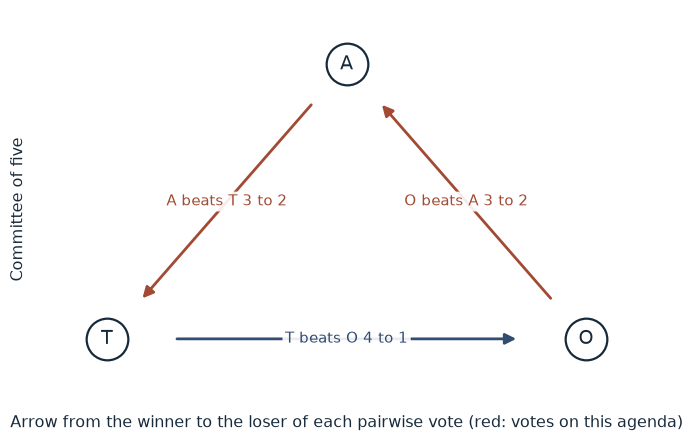

A vs T            3 to 2
T vs O            4 to 1
O vs A            3 to 2
First vote        A vs T: A wins
Winner            outsourcing (O)
Condorcet winner  none (cycle)

Worked steps:
  1. A vs T: 3 to 2, A survives
  2. A vs O: 2 to 3, O wins
  3. Majority preference cycles, so whoever sets the agenda picks the winner.

Member 5 ranks O > A > T. First A meets T: 3 + 2 = 5 votes, A gets 3 and T gets 2, so A survives. Then A meets O, 2 to 3, so O wins. Majority preference cycles, so whoever sets the agenda picks the winner.


In [2]:
show(agenda_picture(agenda='AT', m5='OAT'))

Change one input, `agenda`, and hold the others at the book's values:

In [3]:
sweep(agenda_picture, 'agenda', ['AT', 'TO', 'OA'], {'m5': 'OAT'}, ['First vote', 'Winner'])

agenda | First vote | Winner
AT | A vs T: A wins | outsourcing (O)
TO | T vs O: T wins | automate (A)
OA | O vs A: O wins | training (T)


Each of the three agendas produces a different winner from the same ballots. If member 5 ranks A > O > T, A beats both rivals and wins under every agenda.

## 2. Arrow's impossibility theorem: a cycle and a single-peaked fix

$$R\succ_M B\succ_M D\succ_M R$$

On the spending line $D<B<R$ the second profile is single-peaked.

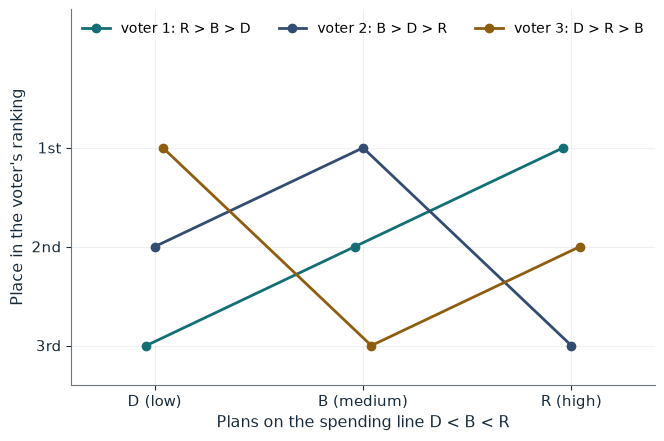

Pairwise results            R over B 2 to 1; B over D 2 to 1; D over R 2 to 1
Single-peaked on D < B < R  no
Majority order              cycle
Majority winner             none

Worked steps:
  1. R vs B: 2 + 1 = 3 votes, 2 to 1
  2. B vs D: 2 + 1 = 3 votes, 2 to 1
  3. D vs R: 2 + 1 = 3 votes, 2 to 1
  4. Order: cycle

Each contest splits the 3 votes, for example R vs B gets 2 + 1 = 3: R over B 2 to 1; B over D 2 to 1; D over R 2 to 1. So the majority relation cycles, so there is no majority order. Voter 3's control applies to the single-peaked profile only.


In [4]:
show(arrow_picture(prof='cyclic', v3='RBD'))

Change one input, `v3`, and hold the others at the book's values:

In [5]:
sweep(arrow_picture, 'v3', ['RBD', 'BRD', 'DBR'], {'prof': 'single'}, ['Single-peaked on D < B < R', 'Majority order'])

v3 | Single-peaked on D < B < R | Majority order
RBD | yes | B > D > R
BRD | yes | B > D > R
DBR | yes | D > B > R


The cyclic profile has no majority order. Every single-peaked profile in the sweep gives a transitive order headed by the median voter's favourite.

## 3. Median voter theorem: the library budget

Ideal budgets in \$ million:

$$(10,25,40,50,65,80,95)$$

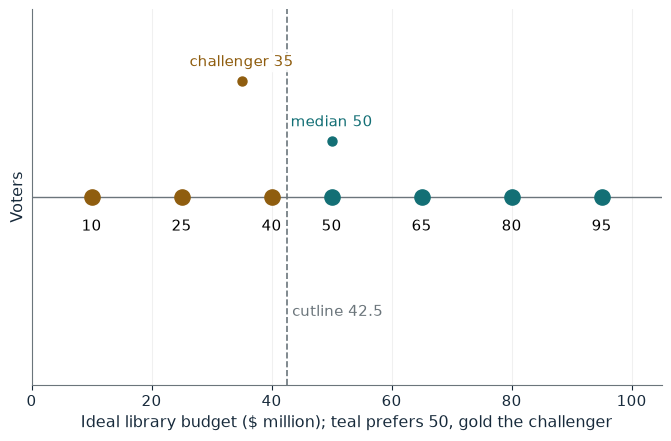

Votes for 50              4
Votes for the challenger  3
Cutline                   42.5
Winner                    50

Worked steps:
  1. Cutline = (50 + 35) / 2 = 42.5
  2. Prefer 50: 50, 65, 80 and 95 = 4 voters
  3. Prefer 35: 3 voters
  4. Result 4 to 3

Voters closer to 50 than to 35 are those on 50's side of the midpoint (50 + 35) / 2 = 42.5: 50, 65, 80 and 95. So 50 wins 4 to 3. The median's coalition always includes the median voter and everyone beyond, so 50 cannot lose.


In [6]:
show(median_picture(c=35))

Change one input, `c`, and hold the others at the book's values:

In [7]:
sweep(median_picture, 'c', [20, 35, 70, 90], {}, ['Votes for 50', 'Votes for the challenger', 'Cutline'])

c | Votes for 50 | Votes for the challenger | Cutline
20 | 5 | 2 | 35
35 | 4 | 3 | 42.5
70 | 4 | 3 | 60
90 | 5 | 2 | 70


The median budget of 50 wins against every challenger: 4 to 3 against 35 and 70, 5 to 2 against 20 and 90.

## 4. Sen's liberal paradox

$$a\succ_P b\succ_P c, \qquad b\succ_L c\succ_L a, \qquad c\succ a\succ b\succ c$$

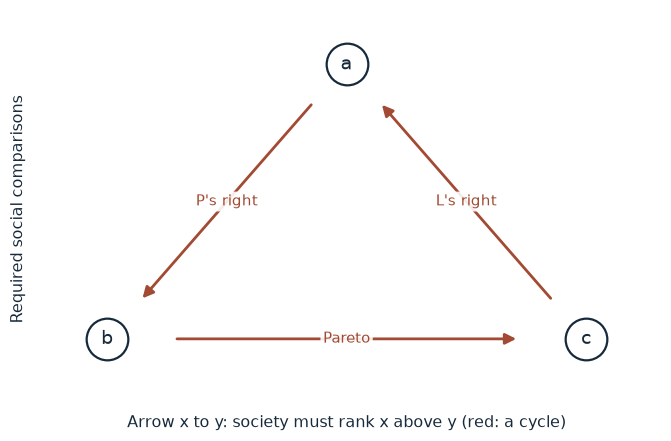

Required comparisons     3
Cycle                    yes
Consistent social order  none

Worked steps:
  1. P's right: a > b
  2. L's right: c > a
  3. Both P and L rank b above c, so Pareto adds b > c.
  4. 3 comparisons: cycle

P's right over a versus b gives a > b; L's right over a versus c gives c > a. Both P and L rank b above c, so Pareto adds b > c. That makes 1 + 1 + 1 = 3 required comparisons, and c > a > b > c is a cycle, so no transitive social order exists.


In [8]:
show(sen_picture(lview='cares', pareto='on'))

Change one input, `lview`, and hold the others at the book's values:

In [9]:
sweep(sen_picture, 'lview', ['cares', 'indifferent'], {'pareto': 'on'}, ['Required comparisons', 'Cycle', 'Consistent social order'])

lview | Required comparisons | Cycle | Consistent social order
cares | 3 | yes | none
indifferent | 2 | no | c > a > b


When L cares about P's reading, the two rights and Pareto form a cycle. If L is indifferent between a and b, Pareto is silent on b versus c and c > a > b works.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

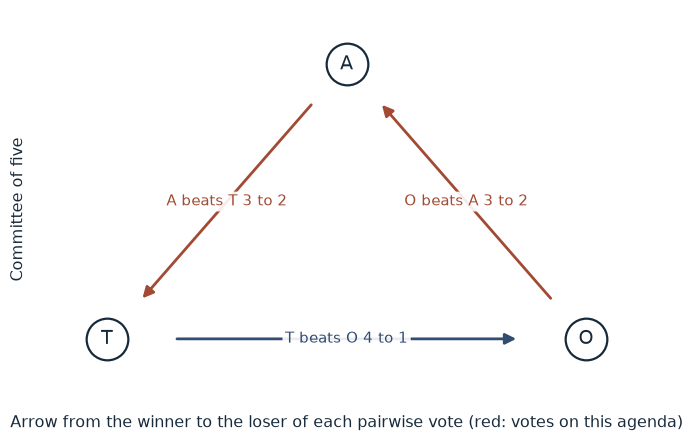

A vs T            3 to 2
T vs O            4 to 1
O vs A            3 to 2
First vote        A vs T: A wins
Winner            outsourcing (O)
Condorcet winner  none (cycle)

Worked steps:
  1. A vs T: 3 to 2, A survives
  2. A vs O: 2 to 3, O wins
  3. Majority preference cycles, so whoever sets the agenda picks the winner.

Member 5 ranks O > A > T. First A meets T: 3 + 2 = 5 votes, A gets 3 and T gets 2, so A survives. Then A meets O, 2 to 3, so O wins. Majority preference cycles, so whoever sets the agenda picks the winner.


In [10]:
show(agenda_picture(agenda='AT', m5='OAT'))

## Practice

**1.** With member 5 at A > O > T and the agenda T vs O first, who wins?

<details><summary>Answer</summary>

T beats O 4 to 1, then A beats T 3 to 2: A wins, as under every agenda.

</details>

**2.** Against a \$90 million challenger, what is the tally?

<details><summary>Answer</summary>

Cutline 70: 5 voters prefer 50, 2 prefer 90.

</details>

**3.** In the single-peaked profile with voter 3 ranking D > B > R, what is the majority order?

<details><summary>Answer</summary>

D > B > R: D beats B 2 to 1, D and B both beat R 3 to 0.

</details>